# Étape 4 : Régression du diamètre

**Client :** NASA/JPL Planetary Defense Coordination Office (PDCO)
**Pourquoi le diamètre ?** C'est lui qui fixe la gravité d'un impact : l'énergie varie comme le diamètre **au cube**. Or 97 % des diamètres du catalogue ne sont pas mesurés, mais calculés à partir de H avec un albédo fixe de 0,14.

**Les deux questions de cette étape :**

1. Peut-on estimer le diamètre **mieux** que la formule à albédo fixe, en apprenant sur les 1 244 diamètres réellement mesurés ?
2. Quelle est **l'incertitude** de cette estimation ? Pour une politique « zéro faux négatif », il faut connaître la taille *plausible maximale* d'un objet, pas seulement sa taille moyenne.

Ce notebook utilise les données préparées à l'étape 3 : exécutez `03_preprocessing.ipynb` avant celui-ci.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor, plot_tree

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def find_project_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / "nasa-project"):
            if (candidate / "data" / "raw").is_dir():
                return candidate
    raise FileNotFoundError("Dossier nasa-project/data/raw introuvable.")

PROJECT_DIR = find_project_dir()
RAW_DIR = PROJECT_DIR / "data" / "raw"
PREP_DIR = PROJECT_DIR / "data" / "processed" / "03_preprocessing"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / "04_diameter"
REPORT_DIR = PROJECT_DIR / "reports" / "04_diameter"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not (PREP_DIR / "diameter_train.csv").exists():
    raise FileNotFoundError("Exécutez d'abord 03_preprocessing.ipynb.")

config = json.loads((PROJECT_DIR / "reports" / "03_preprocessing" / "config_preprocessing.json").read_text(encoding="utf-8"))
RANDOM_STATE = config["random_state"]
NUM = config["diameter_regression"]["features"]["numeric"]
CAT = config["diameter_regression"]["features"]["categorical"]
FEATURES = NUM + CAT
TARGET = config["diameter_regression"]["target"]

train = pd.read_csv(PREP_DIR / "diameter_train.csv")
test = pd.read_csv(PREP_DIR / "diameter_test.csv")
preprocessor = joblib.load(PREP_DIR / "preprocessor_diameter.joblib")   # non ajusté

BLUE, ORANGE, GREY, RED, GREEN = "#2878B5", "#E07A2D", "#8C8C8C", "#C0392B", "#3A8F5C"
LABEL_BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

def save(fig, name):
    fig.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def fmt(n):
    return f"{n:,.0f}".replace(",", " ")

print(f"Variables : {FEATURES} | cible : {TARGET}")
print(f"Train : {len(train)} objets | Test : {len(test)} objets")

Variables : ['H', 'a', 'e', 'i', 'q', 'ad', 'class'] | cible : log10_diameter_km
Train : 995 objets | Test : 249 objets


## 1. Partir de la physique

La relation entre diamètre D (km), magnitude absolue H et albédo p est connue :

$$\log_{10} D = \underbrace{\log_{10} 1329 - \tfrac{1}{2}\log_{10} p}_{\text{terme d'albédo, inconnu}} \;-\; \underbrace{H/5}_{\text{connu exactement}}$$

Le seul inconnu est l'albédo. Deux stratégies sont donc possibles :

- **Directe** : le modèle prédit log₁₀ D à partir de H et de l'orbite. Il doit réapprendre la pente −1/5 sur H.
- **Guidée par la physique** : on garde le terme −H/5 exact, et le modèle ne prédit que le **terme d'albédo** `r = log₁₀ D + H/5`. Il apprend donc *à quel point l'objet est sombre ou clair*, à partir de son orbite et de sa taille.

La seconde est particulièrement adaptée aux arbres : un arbre approche une droite par paliers, alors qu'il gère bien un terme d'albédo qui varie peu.

In [2]:
LOG_K = np.log10(1329)

def albedo_term(df):
    return df[TARGET] + df["H"] / 5

def to_log_diameter(albedo_term_pred, H):
    return albedo_term_pred - H / 5

def term_to_albedo(term):
    return 10 ** (2 * (LOG_K - term))

y_train, y_test = train[TARGET], test[TARGET]
r_train = albedo_term(train)

def metrics(y_true, y_pred) -> dict:
    err = np.asarray(y_pred) - np.asarray(y_true)
    return {
        "RMSE (dex)": np.sqrt(np.mean(err ** 2)),
        "R²": 1 - np.sum(err ** 2) / np.sum((y_true - np.mean(y_true)) ** 2),
        "facteur d'erreur médian": 10 ** np.median(np.abs(err)),
        "% à ±30 %": np.mean(np.abs(err) < np.log10(1.3)) * 100,
        "% faux d'un facteur > 2": np.mean(np.abs(err) > np.log10(2)) * 100,
        "biais (dex)": np.mean(err),
    }

**Comment lire les métriques :**

- **RMSE en dex** : erreur moyenne sur log₁₀ D. Une erreur de 0,2 dex correspond à un facteur 10^0,2 ≈ 1,6 sur le diamètre.
- **Facteur d'erreur médian** : pour la moitié des objets, le diamètre prédit est à moins de ce facteur du vrai diamètre (1,4 = ±40 %).
- **% faux d'un facteur > 2** : la part des erreurs graves, celles qui comptent pour la PDCO.
- **R²** : il paraît élevé (≈ 0,8) dès qu'on utilise H, car H explique à lui seul l'essentiel des écarts de taille. C'est la comparaison avec la formule de référence qui dit si le modèle apporte quelque chose.

## 2. Comparaison des modèles en validation croisée (train uniquement)

Validation croisée à 5 plis sur le train. Le test n'est utilisé qu'une seule fois, à la section 3.

In [3]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def pipe(model):
    return Pipeline([("prep", clone(preprocessor)), ("model", model)])

candidates = {
    "Formule catalogue (albédo 0,14)": None,
    "Albédo moyen appris": ("résiduel", pipe(DummyRegressor())),
    "Linéaire directe": ("direct", pipe(LinearRegression())),
    "Arbre direct (profondeur 6)": ("direct", pipe(DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=RANDOM_STATE))),
    "Arbre physique (profondeur 3)": ("résiduel", pipe(DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=RANDOM_STATE))),
    "Random Forest physique": ("résiduel", pipe(RandomForestRegressor(n_estimators=400, min_samples_leaf=10, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE))),
}

cv_rows, oof = [], {}
for name, spec in candidates.items():
    if spec is None:
        pred = np.log10(1329 / np.sqrt(0.14)) - train["H"] / 5
    else:
        kind, model = spec
        if kind == "direct":
            pred = cross_val_predict(model, train[FEATURES], y_train, cv=cv)
        else:
            pred = to_log_diameter(cross_val_predict(model, train[FEATURES], r_train, cv=cv), train["H"])
    oof[name] = np.asarray(pred)
    cv_rows.append({"modèle": name, **metrics(y_train, pred)})

cv_table = pd.DataFrame(cv_rows).set_index("modèle")
cv_table.to_csv(REPORT_DIR / "comparaison_modeles_cv.csv")
cv_table.round(3)

,RMSE (dex),R²,facteur d'erreur médian,% à ±30 %,% faux d'un facteur > 2,biais (dex)
modèle,,,,,,
"Formule catalogue (albédo 0,14)",0.219,0.797,1.438,36.784,17.387,-0.045
Albédo moyen appris,0.215,0.805,1.475,34.171,15.075,0.000
Linéaire directe,0.198,0.834,1.409,38.291,11.759,0.001
Arbre direct (profondeur 6),0.223,0.789,1.410,39.598,17.990,-0.001
Arbre physique (profondeur 3),0.202,0.827,1.408,38.291,12.060,-0.002
Random Forest physique,0.195,0.839,1.379,39.397,10.955,-0.001


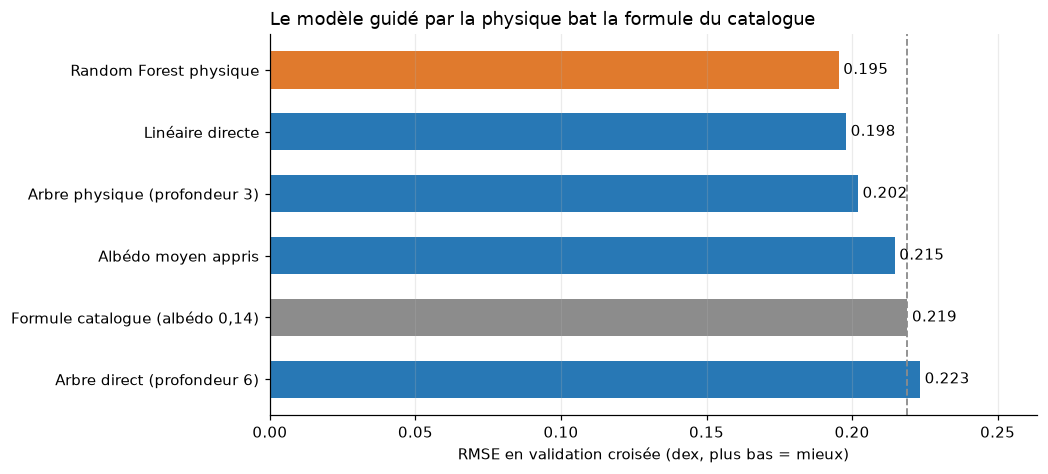

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = cv_table["RMSE (dex)"].sort_values(ascending=False)
colors = [GREY if "Formule" in n else (ORANGE if "Random Forest" in n else BLUE) for n in order.index]
bars = ax.barh(order.index, order.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in order.values], padding=3)
ref = cv_table.loc["Formule catalogue (albédo 0,14)", "RMSE (dex)"]
ax.axvline(ref, color=GREY, ls="--", lw=1.2)
ax.set_xlim(0, order.max() * 1.18)
ax.set_xlabel("RMSE en validation croisée (dex, plus bas = mieux)")
ax.set_title("Le modèle guidé par la physique bat la formule du catalogue", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "comparaison_modeles_cv")
plt.show()

**Lecture :**

- **L'arbre direct est le moins bon**, plus mauvais que la formule elle-même : il approche la droite log D = f(H) par paliers. C'est la justification de l'approche guidée par la physique.
- **Apprendre l'albédo moyen des objets mesurés** corrige déjà le biais de la formule : les objets mesurés sont en moyenne un peu plus sombres que 0,14.
- **Le Random Forest physique** donne la plus faible erreur. Le gain sur la formule est réel mais modeste : l'albédo d'un astéroïde ne se devine que partiellement à partir de son orbite.

On règle maintenant les hyperparamètres du Random Forest par recherche en grille, toujours en validation croisée sur le train.

In [5]:
grid = GridSearchCV(
    pipe(RandomForestRegressor(n_estimators=400, n_jobs=-1, random_state=RANDOM_STATE)),
    param_grid={"model__min_samples_leaf": [5, 10, 20, 40], "model__max_features": [0.3, 0.5, 1.0]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1,
)
grid.fit(train[FEATURES], r_train)   # RMSE sur le terme d'albédo = RMSE sur log D (même décalage exact)

grid_results = (pd.DataFrame(grid.cv_results_)
                .assign(RMSE=lambda d: -d["mean_test_score"])
                [["param_model__min_samples_leaf", "param_model__max_features", "RMSE", "std_test_score"]]
                .sort_values("RMSE"))
grid_results.to_csv(REPORT_DIR / "grid_search_rf.csv", index=False)
print("Meilleurs paramètres :", grid.best_params_, f"| RMSE CV = {-grid.best_score_:.3f} dex")
grid_results.head(5)

Meilleurs paramètres : {'model__max_features': 1.0, 'model__min_samples_leaf': 20} | RMSE CV = 0.195 dex


,param_model__min_samples_leaf,param_model__max_features,RMSE,std_test_score
10,20,1.000,0.195,0.015
9,10,1.000,0.195,0.014
5,10,0.500,0.195,0.014
6,20,0.500,0.195,0.015
1,10,0.300,0.195,0.014


## 3. Évaluation finale sur le test (une seule fois)

On réentraîne les trois modèles de référence sur **tout le train**, puis on les évalue sur les 249 objets du test, jamais vus jusque-là.

In [6]:
final_models = {
    "Formule catalogue (albédo 0,14)": None,
    "Linéaire directe": ("direct", pipe(LinearRegression()).fit(train[FEATURES], y_train)),
    "Random Forest physique": ("résiduel", grid.best_estimator_),
}

def predict_log_d(spec, df):
    if spec is None:
        return np.log10(1329 / np.sqrt(0.14)) - df["H"] / 5
    kind, model = spec
    pred = model.predict(df[FEATURES])
    return pred if kind == "direct" else to_log_diameter(pred, df["H"])

test_preds = {name: np.asarray(predict_log_d(spec, test)) for name, spec in final_models.items()}
test_table = pd.DataFrame([{"modèle": n, **metrics(y_test, p)} for n, p in test_preds.items()]).set_index("modèle")
test_table.to_csv(REPORT_DIR / "metriques_test.csv")

gain = 1 - test_table.loc["Random Forest physique", "RMSE (dex)"] / test_table.loc["Formule catalogue (albédo 0,14)", "RMSE (dex)"]
print(f"Réduction de l'erreur (RMSE) par rapport à la formule du catalogue : {gain:.0%}")
test_table.round(3)

Réduction de l'erreur (RMSE) par rapport à la formule du catalogue : 9%


,RMSE (dex),R²,facteur d'erreur médian,% à ±30 %,% faux d'un facteur > 2,biais (dex)
modèle,,,,,,
"Formule catalogue (albédo 0,14)",0.222,0.811,1.472,35.743,20.080,-0.055
Linéaire directe,0.200,0.847,1.435,36.546,11.245,-0.016
Random Forest physique,0.203,0.842,1.430,36.948,12.048,-0.019


**Lecture honnête du test :**

- **Contre la formule du catalogue**, le gain est net sur les erreurs graves : la part des diamètres faux d'un facteur supérieur à 2 passe d'environ **20 % à 12 %**. Le biais (sous-estimation systématique de la formule) est aussi réduit.
- **Entre le Random Forest et le modèle linéaire**, l'écart sur le test est plus petit que la variabilité observée d'un pli à l'autre en validation croisée (± 0,015 dex). Les deux modèles sont donc **à égalité en précision**.
- **On retient le Random Forest** pour une raison qui ne se voit pas dans ces métriques : son comportement sur les petits objets, absents des données d'entraînement (section 6).

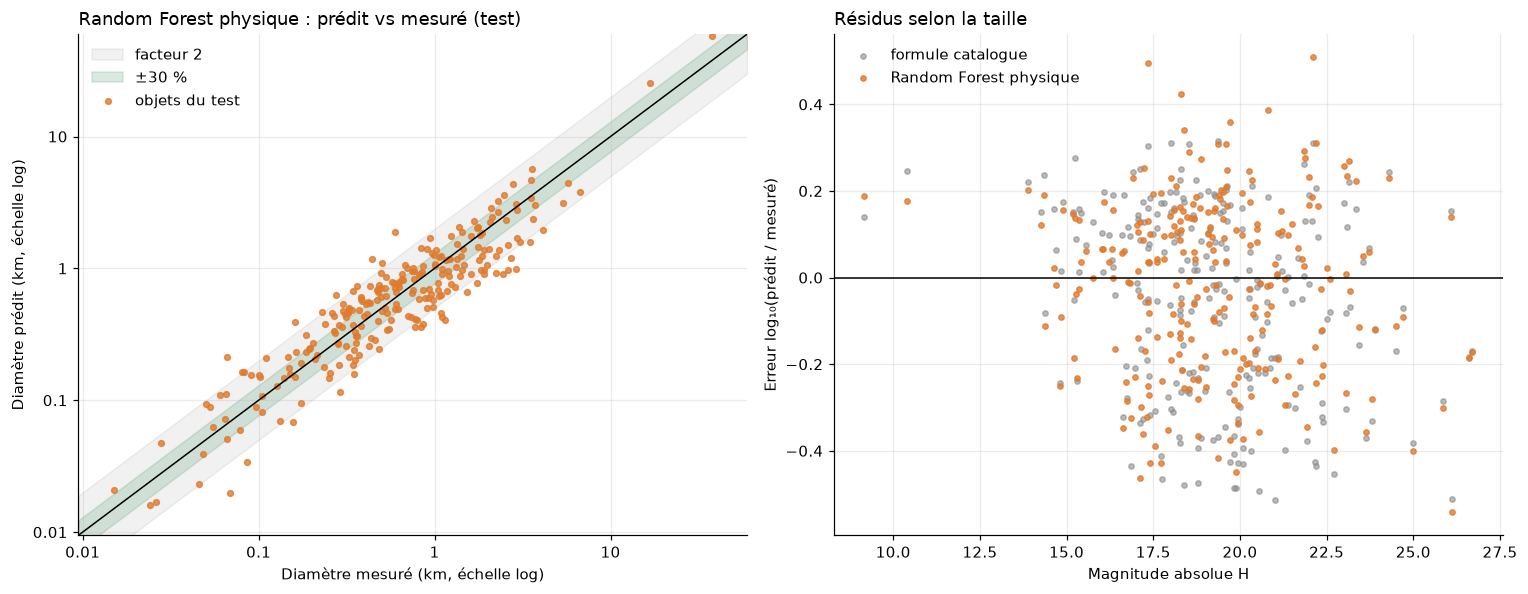

In [7]:
best = test_preds["Random Forest physique"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
lims = np.array([y_test.min() - 0.2, y_test.max() + 0.2])
ax.fill_between(lims, lims - np.log10(2), lims + np.log10(2), color=GREY, alpha=0.12, label="facteur 2")
ax.fill_between(lims, lims - np.log10(1.3), lims + np.log10(1.3), color=GREEN, alpha=0.18, label="±30 %")
ax.plot(lims, lims, color="black", lw=1)
ax.scatter(y_test, best, s=14, color=ORANGE, alpha=0.8, label="objets du test")
ticks = np.arange(np.floor(lims[0]), np.ceil(lims[1]) + 1)
ax.set_xticks(ticks, [f"{10**t:g}" for t in ticks])
ax.set_yticks(ticks, [f"{10**t:g}" for t in ticks])
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Diamètre mesuré (km, échelle log)")
ax.set_ylabel("Diamètre prédit (km, échelle log)")
ax.set_title("Random Forest physique : prédit vs mesuré (test)", loc="left")
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
err_formula = test_preds["Formule catalogue (albédo 0,14)"] - y_test
err_rf = best - y_test
ax.axhline(0, color="black", lw=1)
ax.scatter(test["H"], err_formula, s=12, color=GREY, alpha=0.6, label="formule catalogue")
ax.scatter(test["H"], err_rf, s=12, color=ORANGE, alpha=0.8, label="Random Forest physique")
ax.set_xlabel("Magnitude absolue H")
ax.set_ylabel("Erreur log₁₀(prédit / mesuré)")
ax.set_title("Résidus selon la taille", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
save(fig, "predit_vs_mesure_test")
plt.show()

## 4. Ce que le modèle a appris

**Importance par permutation** (sur le test) : on mélange une variable à la fois et on mesure la hausse de l'erreur. Plus la hausse est forte, plus le modèle dépend de cette variable.

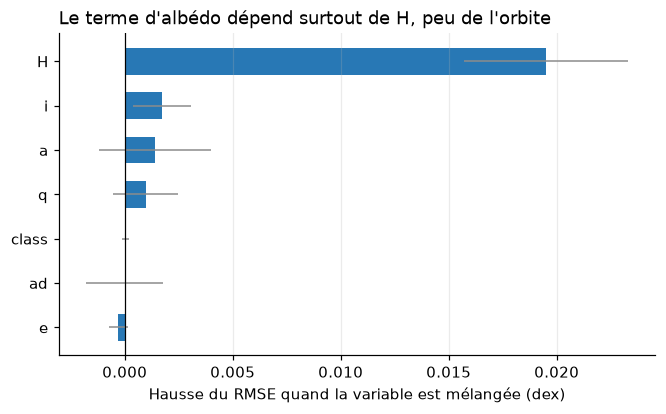

In [8]:
perm = permutation_importance(grid.best_estimator_, test[FEATURES], albedo_term(test),
                              scoring="neg_root_mean_squared_error", n_repeats=20,
                              random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
importance.rename("hausse du RMSE (dex)").to_csv(REPORT_DIR / "importance_permutation.csv")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(importance.index, importance.values, xerr=perm.importances_std[np.argsort(perm.importances_mean)],
        color=BLUE, height=0.6, error_kw={"ecolor": GREY, "lw": 1})
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Hausse du RMSE quand la variable est mélangée (dex)")
ax.set_title("Le terme d'albédo dépend surtout de H, peu de l'orbite", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "importance_permutation")
plt.show()

**Lecture :** H reste la variable la plus utile, même pour prédire l'albédo. Parmi les objets mesurés, les petits sont en moyenne plus sombres que les gros. Il y a deux explications possibles, qu'on ne peut pas départager ici :

- un effet physique réel (composition différente selon la taille) ;
- un **biais de sélection** : les mesures infrarouges (NEOWISE) détectent mieux les objets sombres et petits, qui émettent plus de chaleur pour leur luminosité.

L'orbite n'apporte qu'un petit complément dans la forêt. C'est un résultat honnête à présenter : **l'albédo d'un géocroiseur se devine mal à partir de son orbite.**

Pour la présentation, voici un arbre peu profond entraîné sur les variables brutes. Il est moins précis que la forêt, mais ses règles se lisent directement. Les valeurs dans les feuilles ont été converties en albédo.

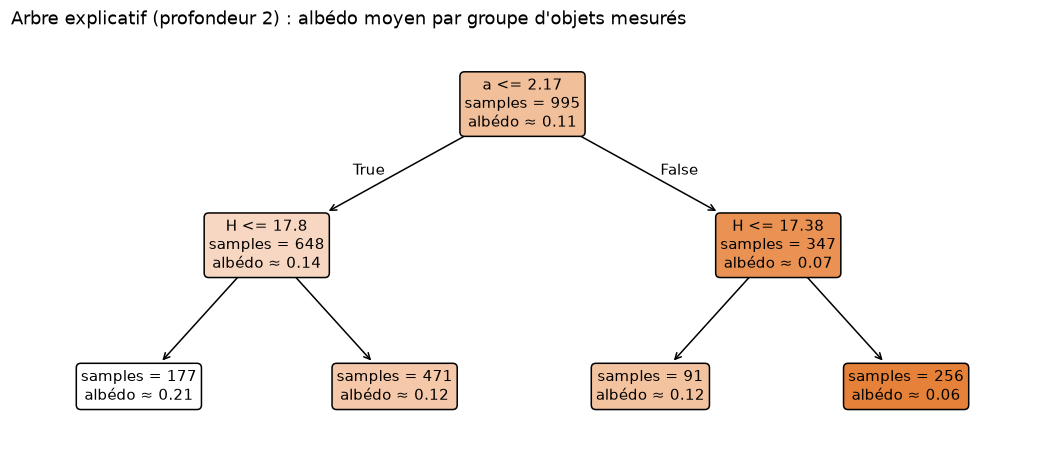

In [9]:
explain_cols = ["H", "a", "e", "i", "q", "ad"]
explainer = DecisionTreeRegressor(max_depth=2, min_samples_leaf=40, random_state=RANDOM_STATE)
explainer.fit(train[explain_cols], r_train)

fig, ax = plt.subplots(figsize=(12, 5))
artists = plot_tree(explainer, feature_names=explain_cols, filled=True, rounded=True,
                    impurity=False, precision=2, fontsize=10, ax=ax)
for t in artists:   # affiche l'albédo équivalent au lieu du terme log
    txt = t.get_text()
    if "value = " in txt:
        head, val = txt.rsplit("value = ", 1)
        t.set_text(f"{head}albédo ≈ {term_to_albedo(float(val)):.2f}")
ax.set_title("Arbre explicatif (profondeur 2) : albédo moyen par groupe d'objets mesurés", loc="left")
save(fig, "arbre_explicatif_albedo")
plt.show()

**Lecture de l'arbre :** la première séparation se fait sur le demi-grand axe. Les objets dont l'orbite s'étend loin (a > 2,17 UA) sont nettement plus sombres, surtout parmi les petits (albédo ≈ 0,06). C'est cohérent avec la physique : ces objets proviennent plutôt de la partie externe de la ceinture principale, riche en astéroïdes carbonés, très sombres. Pour eux, la formule du catalogue (albédo 0,14) **sous-estime le diamètre d'environ un tiers**.

## 5. Quantifier l'incertitude

Un diamètre seul ne suffit pas à la PDCO : il faut savoir **jusqu'où il peut monter**. On construit un intervalle à partir des erreurs du modèle **en validation croisée sur le train** (prédictions hors pli), puis on vérifie sur le test qu'il contient bien la proportion attendue de vrais diamètres.

- **Intervalle à 90 %** : entre les quantiles 5 % et 95 % des erreurs hors pli.
- **Diamètre pessimiste** : la borne haute. C'est celui à utiliser pour une politique « zéro faux négatif ».

In [10]:
oof_rf = to_log_diameter(cross_val_predict(clone(grid.best_estimator_), train[FEATURES], r_train, cv=cv), train["H"])
oof_err = y_train - oof_rf          # vrai − prédit
q_low, q_high = np.quantile(oof_err, [0.05, 0.95])
print(f"Intervalle à 90 % : de ×{10**q_low:.2f} à ×{10**q_high:.2f} autour du diamètre prédit")

inside = (y_test >= best + q_low) & (y_test <= best + q_high)
print(f"Couverture sur le test : {inside.mean():.1%} des vrais diamètres dans l'intervalle (cible : 90 %)")

bins = pd.cut(test["H"], [0, 16, 18, 20, 22, 40], labels=["H ≤ 16", "16–18", "18–20", "20–22", "H > 22"])
coverage = (pd.DataFrame({"tranche de H": bins, "dans l'intervalle": inside, "erreur": best - y_test})
            .groupby("tranche de H", observed=True)
            .agg(objets=("erreur", "size"),
                 couverture=("dans l'intervalle", "mean"),
                 facteur_erreur_median=("erreur", lambda e: 10 ** np.median(np.abs(e)))))
coverage.to_csv(REPORT_DIR / "couverture_par_tranche.csv")
coverage

Intervalle à 90 % : de ×0.52 à ×2.14 autour du diamètre prédit
Couverture sur le test : 88.0% des vrais diamètres dans l'intervalle (cible : 90 %)


,objets,couverture,facteur_erreur_median
tranche de H,,,
H ≤ 16,21,1.000,1.359
16–18,55,0.855,1.371
18–20,86,0.872,1.440
20–22,52,0.904,1.445
H > 22,35,0.829,1.532


## 6. Domaine de validité : le modèle peut-il prédire les petits objets ?

Le modèle a appris sur des objets surtout gros. Une forêt aléatoire ne prolonge pas les tendances au-delà de ses données : pour un H plus grand que tout ce qu'elle a vu, elle renvoie la valeur de ses feuilles les plus proches. C'est une propriété **prudente**, contrairement à un modèle linéaire qui prolongerait la pente jusqu'à des albédos absurdes. On le vérifie en traçant l'albédo implicite prédit sur une plage de H.

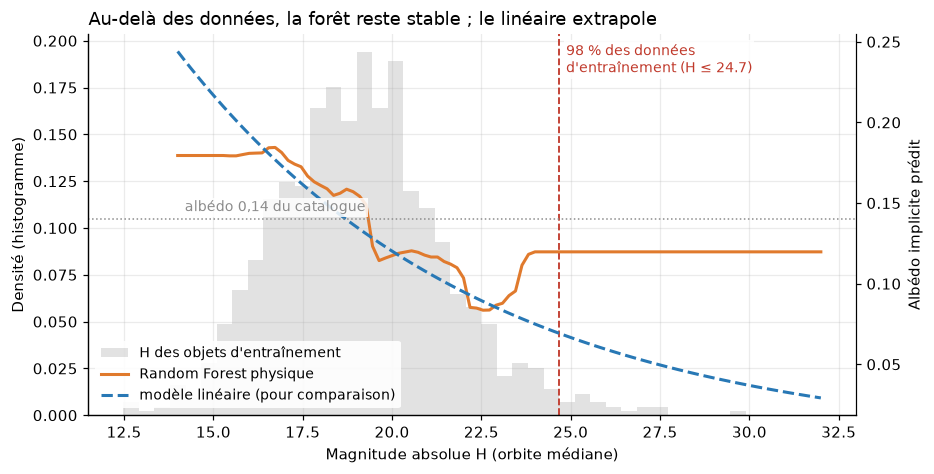

In [12]:
H_grid = np.linspace(14, 32, 100)
median_orbit = train[["a", "e", "i", "q", "ad"]].median()
grid_df = pd.DataFrame({"H": H_grid, **{c: median_orbit[c] for c in median_orbit.index},
                        "class": train["class"].mode()[0]})

lin_resid = pipe(LinearRegression()).fit(train[FEATURES], r_train)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(train["H"], bins=40, density=True, color=GREY, alpha=0.25, label="H des objets d'entraînement")
ax2 = ax.twinx()
ax2.plot(H_grid, term_to_albedo(grid.best_estimator_.predict(grid_df[FEATURES])), color=ORANGE, lw=2, label="Random Forest physique")
ax2.plot(H_grid, term_to_albedo(lin_resid.predict(grid_df[FEATURES])), color=BLUE, lw=2, ls="--", label="modèle linéaire (pour comparaison)")
ax2.axhline(0.14, color=GREY, lw=1, ls=":")
ax2.text(14.2, 0.145, "albédo 0,14 du catalogue", color=GREY, fontsize=9, bbox=LABEL_BOX)
H_LIMIT = float(np.quantile(train["H"], 0.98))
ax.axvline(H_LIMIT, color=RED, ls="--", lw=1.2)
ax.text(H_LIMIT + 0.2, ax.get_ylim()[1] * 0.9, f"98 % des données\nd'entraînement (H ≤ {H_LIMIT:.1f})", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("Magnitude absolue H (orbite médiane)")
ax.set_ylabel("Densité (histogramme)")
ax2.set_ylabel("Albédo implicite prédit")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title("Au-delà des données, la forêt reste stable ; le linéaire extrapole", loc="left")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, frameon=True, framealpha=0.9, edgecolor="none", loc="lower left", fontsize=9)
save(fig, "domaine_validite")
plt.show()

## 7. Application à tout le catalogue

Pour chaque objet :

- si le diamètre est **mesuré**, on le garde ;
- sinon, on utilise la **prédiction du Random Forest physique**, avec son intervalle à 90 % ;
- un drapeau `hors_domaine` signale les objets plus petits que 98 % des objets d'entraînement : leur prédiction s'appuie sur très peu d'exemples.

Ce tableau alimentera le calcul d'énergie et le score de priorité de l'étape 7.

In [13]:
catalogue = pd.read_csv(sorted(RAW_DIR.glob("near_earth_asteroids_2025*.csv"))[0], low_memory=False)
cat = catalogue[["pdes", "H", "diameter_km", "diameter_is_estimated", "albedo"] + [c for c in FEATURES if c != "H"]].copy()

log_pred = np.asarray(to_log_diameter(grid.best_estimator_.predict(cat[FEATURES]), cat["H"]))
measured = ~cat["diameter_is_estimated"]

out = pd.DataFrame({
    "pdes": cat["pdes"],
    "H": cat["H"],
    "source_diametre": np.where(measured, "mesuré", "prédit"),
    "diametre_km": np.where(measured, cat["diameter_km"], 10 ** log_pred),
    "diametre_km_bas": np.where(measured, cat["diameter_km"], 10 ** (log_pred + q_low)),
    "diametre_km_haut": np.where(measured, cat["diameter_km"], 10 ** (log_pred + q_high)),
    "diametre_catalogue_km": cat["diameter_km"],
    "hors_domaine": (~measured) & (cat["H"] > H_LIMIT),
})
out.to_csv(PROCESSED_DIR / "catalogue_diametres.csv", index=False)
joblib.dump(grid.best_estimator_, PROCESSED_DIR / "rf_albedo_term.joblib")
(REPORT_DIR / "intervalle.json").write_text(json.dumps(
    {"q_low_dex": q_low, "q_high_dex": q_high, "H_limit": H_LIMIT, "best_params": grid.best_params_},
    indent=2, ensure_ascii=False), encoding="utf-8")

pred_rows = out[out["source_diametre"] == "prédit"]
summary = pd.DataFrame({
    "indicateur": [
        "Objets au catalogue",
        "Diamètres mesurés (gardés tels quels)",
        "Diamètres prédits par le modèle",
        "dont hors domaine (H > limite)",
        "Objets ≥ 140 m selon le catalogue",
        "Objets ≥ 140 m selon le modèle",
        "Objets ≥ 140 m selon la borne haute (pessimiste)",
    ],
    "valeur": [
        fmt(len(out)), fmt(measured.sum()), fmt(len(pred_rows)), fmt(out["hors_domaine"].sum()),
        fmt((out["diametre_catalogue_km"] >= 0.14).sum()),
        fmt((out["diametre_km"] >= 0.14).sum()),
        fmt((out["diametre_km_haut"] >= 0.14).sum()),
    ],
})
summary.to_csv(REPORT_DIR / "synthese_catalogue.csv", index=False)
summary

,indicateur,valeur
0,Objets au catalogue,41 281
1,Diamètres mesurés (gardés tels quels),1 246
2,Diamètres prédits par le modèle,40 035
3,dont hors domaine (H > limite),16 883
4,Objets ≥ 140 m selon le catalogue,11 667
5,Objets ≥ 140 m selon le modèle,14 020
6,Objets ≥ 140 m selon la borne haute (pessimiste),20 059


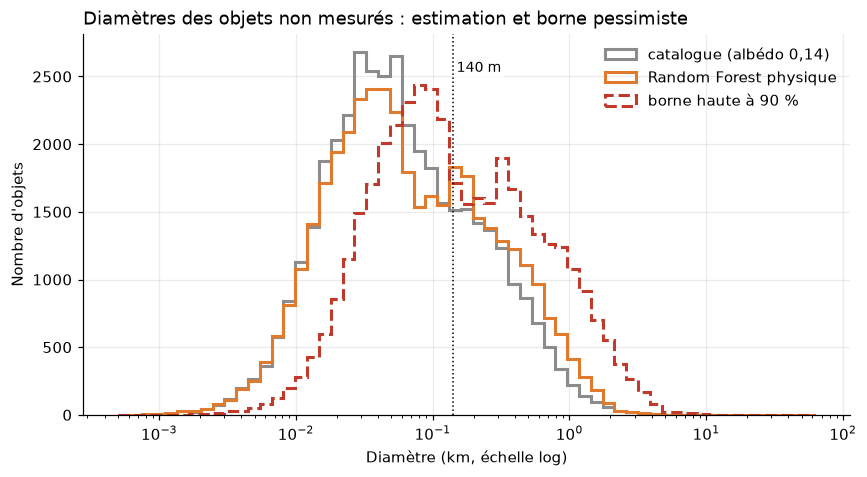

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.logspace(-3.3, 1.8, 60)
ax.hist(pred_rows["diametre_catalogue_km"], bins=bins, histtype="step", lw=2, color=GREY, label="catalogue (albédo 0,14)")
ax.hist(pred_rows["diametre_km"], bins=bins, histtype="step", lw=2, color=ORANGE, label="Random Forest physique")
ax.hist(pred_rows["diametre_km_haut"], bins=bins, histtype="step", lw=2, ls="--", color=RED, label="borne haute à 90 %")
ax.axvline(0.14, color="black", lw=1, ls=":")
ax.text(0.15, ax.get_ylim()[1] * 0.9, "140 m", fontsize=9, bbox=LABEL_BOX)
ax.set_xscale("log")
ax.set_xlabel("Diamètre (km, échelle log)")
ax.set_ylabel("Nombre d'objets")
ax.set_title("Diamètres des objets non mesurés : estimation et borne pessimiste", loc="left")
ax.legend(frameon=False)
save(fig, "diametres_catalogue")
plt.show()

## Synthèse

| Question | Réponse |
|---|---|
| Faire mieux que la formule du catalogue ? | **Oui, modestement** : l'erreur moyenne baisse d'environ 9 % et les erreurs d'un facteur supérieur à 2 passent de 20 % à 12 % des objets. L'albédo reste en grande partie imprévisible à partir de l'orbite. |
| Random Forest ou linéaire ? | Précision équivalente sur le test ; la forêt est retenue car elle n'extrapole pas de tendance absurde aux petits objets. |
| Pourquoi guider le modèle par la physique ? | Un arbre approche mal la relation linéaire log D = f(H) ; en ne prédisant que le terme d'albédo, il garde la loi exacte et n'apprend que l'inconnu. |
| Quelle incertitude ? | Intervalle à 90 % calibré en validation croisée et vérifié sur le test. Un diamètre estimé peut être faux d'un facteur proche de 2. |
| Limite principale | Les objets mesurés sont surtout gros : 41 % du catalogue est plus petit que 98 % des objets d'entraînement et porte le drapeau `hors_domaine`. |
| Effet sur le catalogue | Le modèle juge les objets un peu plus sombres que 0,14 en moyenne : plus d'objets dépassent 140 m qu'avec la formule du catalogue, et encore plus avec la borne haute. |
| Pour l'étape 7 | Utiliser `diametre_km_haut` (pessimiste) pour la priorité, conformément à la politique « zéro faux négatif » ; l'énergie variant comme D³, l'écart entre estimation et borne haute est fortement amplifié. |